Matplotlib is building the font cache; this may take a moment.


268 clear observations

Detected rotation:
  2017: winter crop (wheat/barley/rapeseed) + autumn green-up
  2018: unclear (peak in month 5)
  2019: winter crop (wheat/barley/rapeseed)
  2020: unclear (peak in month 6)
  2021: winter crop (wheat/barley/rapeseed)
  2022: unclear (peak in month 6)
  2023: unclear (peak in month 6)
  2024: winter crop (wheat/barley/rapeseed) + autumn green-up
  2025: unclear (peak in month 6)

Share of observations bare, by month:
month
1     31.0
2     17.0
3      5.0
4      0.0
5      0.0
6      0.0
7      0.0
8      0.0
9      8.0
10     0.0
11    17.0
12    10.0


/tmp/ipykernel_36641/3705999204.py:157: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  ax1.plot(g["date"].dt.dayofyear, g["ndvi"], marker=".", lw=1, label=f"{y}: {rotation[y]}")
/tmp/ipykernel_36641/3705999204.py:157: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  ax1.plot(g["date"].dt.dayofyear, g["ndvi"], marker=".", lw=1, label=f"{y}: {rotation[y]}")
/tmp/ipykernel_36641/3705999204.py:157: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  ax1.plot(g["date"].dt.dayofyear, g["ndvi"], marker=".", lw=1, label=f"{y}: {rotation[y]}")
/tmp/ipykernel_36641/3705999204.py:157: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  ax1.plot(g["date"].dt.dayofyear, g["ndvi"], marker=".",

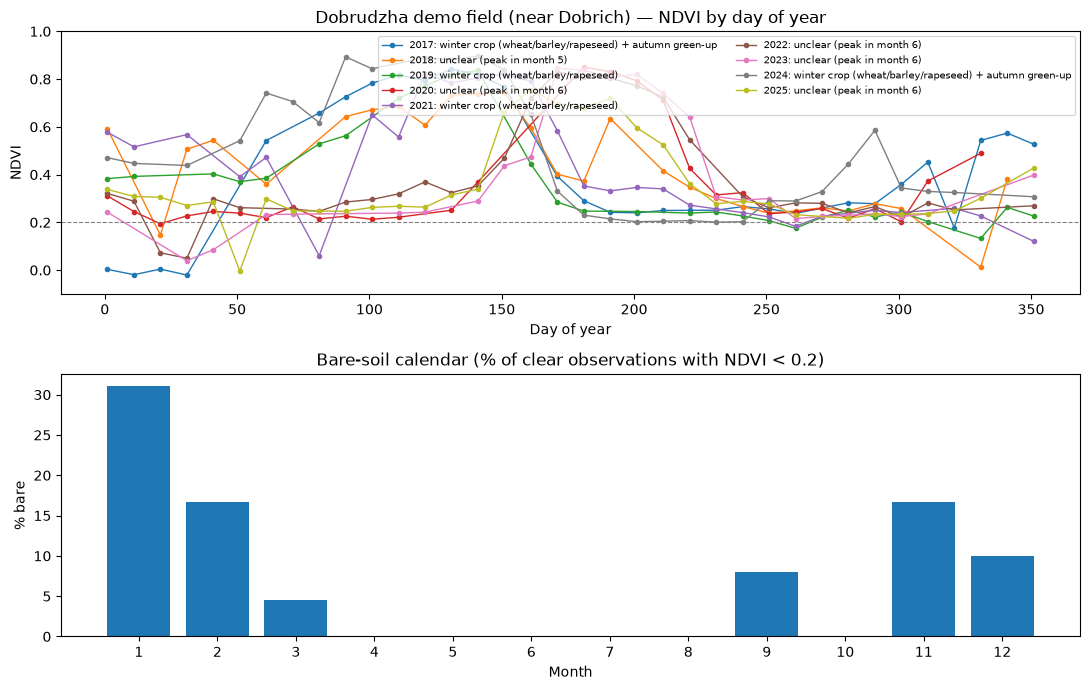

In [5]:

# %% [markdown]
# # Field Shift — Sentinel-2 NDVI for a Dobrudzha field (Bulgaria)
# Pulls a cloud-masked NDVI/NDMI time series for one field (2017–2025) via the
# Sentinel Hub Statistical API, guesses the crop each year from the NDVI curve,
# and builds a "bare-soil calendar".
#
# pip install sentinelhub pandas matplotlib
# export SH_CLIENT_ID=...  SH_CLIENT_SECRET=...

# %% Imports & config
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Polygon
from sentinelhub import (
    SHConfig, SentinelHubStatistical, DataCollection, Geometry, CRS, MosaickingOrder,
)

USE_CDSE = True  # True: Copernicus Data Space account; False: commercial Sentinel Hub

config = SHConfig()
config.sh_client_id = os.environ["SH_CLIENT_ID"]
config.sh_client_secret = os.environ["SH_CLIENT_SECRET"]
if USE_CDSE:
    config.sh_base_url = "https://sh.dataspace.copernicus.eu"
    config.sh_token_url = (
        "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
    )
    S2 = DataCollection.SENTINEL2_L2A.define_from("s2l2a_cdse", service_url=config.sh_base_url)
else:
    S2 = DataCollection.SENTINEL2_L2A

# %% The field
# Approximate ~480 m x 400 m rectangle in the cropland north-east of Dobrich.
# Replace with a real parcel outline: draw it at https://geojson.io and paste the (lon, lat) ring.
FIELD_NAME = "Dobrudzha demo field (near Dobrich)"
field = Polygon([
    (27.930, 43.6100), (27.936, 43.6100), (27.936, 43.6136), (27.930, 43.6136), (27.930, 43.6100),
])
# Statistical API resolution is in CRS units -> use metres (Dobrich is in UTM zone 35N)
geom = Geometry(field, CRS.WGS84).transform(CRS.UTM_35N)

YEARS = range(2017, 2026)
CACHE = Path("cache") / "dobrudzha_ndvi.csv"

# %% Evalscript: NDVI + NDMI, clouds/shadows masked with the Scene Classification Layer
EVALSCRIPT = """
//VERSION=3
function setup() {
  return {
    input: [{ bands: ["B04", "B08", "B11", "SCL", "dataMask"] }],
    output: [
      { id: "ndvi", bands: 1, sampleType: "FLOAT32" },
      { id: "ndmi", bands: 1, sampleType: "FLOAT32" },
      { id: "dataMask", bands: 1 }
    ]
  };
}
function evaluatePixel(s) {
  // SCL 3 = cloud shadow, 8/9 = cloud, 10 = cirrus
  const clear = [3, 8, 9, 10].includes(s.SCL) ? 0 : 1;
  const ndvi = (s.B08 - s.B04) / (s.B08 + s.B04);
  const ndmi = (s.B08 - s.B11) / (s.B08 + s.B11);
  return { ndvi: [ndvi], ndmi: [ndmi], dataMask: [s.dataMask * clear] };
}
"""

# %% Fetch (one request per year, cached to CSV)
def _num(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan


def fetch_year(year: int) -> pd.DataFrame:
    req = SentinelHubStatistical(
        aggregation=SentinelHubStatistical.aggregation(
            evalscript=EVALSCRIPT,
            time_interval=(f"{year}-01-01", f"{year}-12-31"),
            aggregation_interval="P10D",
            resolution=(10, 10),
        ),
        # least cloudy scene inside each 10-day bin
        input_data=[SentinelHubStatistical.input_data(S2, mosaicking_order=MosaickingOrder.LEAST_CC)],
        geometry=geom,
        config=config,
    )
    rows = []
    for iv in req.get_data()[0]["data"]:
        if "error" in iv:
            continue
        ndvi = iv["outputs"]["ndvi"]["bands"]["B0"]["stats"]
        ndmi = iv["outputs"]["ndmi"]["bands"]["B0"]["stats"]
        n, nodata = ndvi["sampleCount"], ndvi["noDataCount"]
        rows.append({
            "date": pd.to_datetime(iv["interval"]["from"][:10]),
            "ndvi": _num(ndvi["mean"]),
            "ndmi": _num(ndmi["mean"]),
            "valid_frac": (n - nodata) / n if n else 0.0,
        })
    return pd.DataFrame(rows)


if CACHE.exists():
    df = pd.read_csv(CACHE, parse_dates=["date"])
else:
    df = pd.concat([fetch_year(y) for y in YEARS], ignore_index=True)
    CACHE.parent.mkdir(exist_ok=True)
    df.to_csv(CACHE, index=False)

# keep bins where at least half the field was cloud-free
df = df[df["valid_frac"] >= 0.5].dropna(subset=["ndvi"]).copy()
df["year"], df["month"] = df["date"].dt.year, df["date"].dt.month
print(f"{len(df)} clear observations")

# %% Guess the crop each year from the shape of the NDVI curve
# Rough rules for the Dobrudzha crop calendar -- a starting point, not a classifier:
#   winter crop (wheat/barley/rapeseed): peak Apr-Jun, harvested by July
#   sunflower: peak Jul, browns fast in Aug-Sep
#   maize: peak Jul-Aug, stays green into Sep
#   second green-up in Sep-Nov after a winter crop: cover crop / volunteer growth
def guess_crop(year_df: pd.DataFrame) -> str:
    m = year_df.groupby("month")["ndvi"].max().reindex(range(1, 13))
    if m.max() < 0.35:
        return "bare / fallow"
    peak = int(m.idxmax())
    if peak in (4, 5, 6) and (m.get(7, np.nan) < 0.35 or np.isnan(m.get(7, np.nan))):
        label = "winter crop (wheat/barley/rapeseed)"
        if m.loc[9:11].max() > 0.5:
            label += " + autumn green-up"
        return label
    if peak in (7, 8):
        return "maize (likely)" if m.get(9, 0) > 0.45 else "sunflower (likely)"
    return f"unclear (peak in month {peak})"


rotation = {y: guess_crop(g) for y, g in df.groupby("year")}
print("\nDetected rotation:")
for y, c in rotation.items():
    print(f"  {y}: {c}")

# %% Bare-soil calendar: share of clear observations per month with NDVI < 0.2
bare = (df.assign(is_bare=df["ndvi"] < 0.2)
          .groupby("month")["is_bare"].mean()
          .reindex(range(1, 13)))
print("\nShare of observations bare, by month:")
print((bare * 100).round(0).to_string())

# %% Plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))

for y, g in df.groupby("year"):
    ax1.plot(g["date"].dt.dayofyear, g["ndvi"], marker=".", lw=1, label=f"{y}: {rotation[y]}")
ax1.axhline(0.2, ls="--", c="grey", lw=0.8)
ax1.set(title=f"{FIELD_NAME} — NDVI by day of year", xlabel="Day of year", ylabel="NDVI", ylim=(-0.1, 1))
ax1.legend(fontsize=7, ncol=2)

ax2.bar(range(1, 13), bare * 100)
ax2.set(title="Bare-soil calendar (% of clear observations with NDVI < 0.2)",
        xticks=range(1, 13), xlabel="Month", ylabel="% bare")

plt.tight_layout()
plt.savefig("dobrudzha_ndvi.png", dpi=150)
plt.show()

In [7]:

import requests


r = requests.get("https://power.larc.nasa.gov/api/temporal/daily/point", params={
    "parameters": "T2M_MAX,T2M_MIN,PRECTOTCORR,GWETROOT,ALLSKY_SFC_SW_DWN",
    "community": "AG", "latitude": 43.61, "longitude": 27.93,
    "start": "20010101", "end": "20251231", "format": "JSON"})
power = pd.DataFrame(r.json()["properties"]["parameter"])
power.index = pd.to_datetime(power.index)        # -999 = missing
print(power)

            T2M_MAX  T2M_MIN  PRECTOTCORR  GWETROOT  ALLSKY_SFC_SW_DWN
2001-01-01     7.97     4.42         7.73      0.42               1.08
2001-01-02     6.35     1.72         2.19      0.44               3.31
2001-01-03     7.49     2.74         0.01      0.44               5.60
2001-01-04     8.34     1.38         0.00      0.43               5.10
2001-01-05     6.83     3.83         0.03      0.43               3.52
...             ...      ...          ...       ...                ...
2025-12-27     2.67    -1.50         0.04      0.59               3.68
2025-12-28     4.46    -0.88         0.25      0.59               4.82
2025-12-29     5.25    -1.21         0.00      0.59               7.45
2025-12-30     5.22    -1.37         0.05      0.59               7.42
2025-12-31     1.83    -2.56         0.01      0.59               7.58

[9131 rows x 5 columns]
